# Assignment 1.2 Individual Benchmarking Code
**Name:** Sanika Mahesh Potphode

## Project goal
Evaluate chemical structure extraction from the six course-provided
scientific PDFs and compare predicted SMILES with the supplied references.

## Dataset
The dataset contains six PDFs: 1, 2, 4, 6, 16, and 19.
The accompanying CSV contains 222 reference molecule entries.

In [37]:
# Load reference molecules and check that all six PDFs exist.
import pandas as pd

course_dataset_dir = reference_files[0].parent
course_references = pd.read_csv(reference_files[0])

print("Reference molecules:", len(course_references))

for paper_id in [1, 2, 4, 6, 16, 19]:
    pdf_path = course_dataset_dir / f"{paper_id}.pdf"
    print(f"{paper_id}.pdf found:", pdf_path.is_file())

display(course_references.head())

Reference molecules: 222
1.pdf found: True
2.pdf found: True
4.pdf found: True
6.pdf found: True
16.pdf found: True
19.pdf found: True


,paperID,name of molecule,canonical_SMILES
0,1,AMG925,C[C@H]1CC[C@H](n2c3cnccc3c3cnc(Nc4ccc5c(n4)CCN...
1,1,AST487,CCN1CCN(Cc2ccc(NC(=O)Nc3ccc(Oc4cc(NC)ncn4)cc3)...
2,1,Axitinib,CNC(=O)c1ccccc1Sc1ccc2c(/C=C/c3ccccn3)n[nH]c2c1
3,1,Bosutinib,COc1cc(Nc2c(C#N)cnc3cc(OCCCN4CCN(C)CC4)c(OC)cc...
4,1,Cabozantinib,COc1cc2nccc(Oc3ccc(NC(=O)C4(C(=O)Nc5ccc(F)cc5)...


In [38]:
# Define project paths and locate the course dataset.
from pathlib import Path

project_dir = Path.cwd()

reference_files = list(project_dir.glob(
    "Dataset 2/Dataset/"
    "ground_truth_SMILES_confirmed_1,2,4,6,16,19.csv"
))

if len(reference_files) != 1:
    raise FileNotFoundError(
        "Expected the reference CSV inside Dataset 2/Dataset. "
        "Extract the course dataset beside this notebook."
    )

print("Project folder:", project_dir)
print("Reference file:", reference_files[0])

Project folder: c:\Users\sanik\OneDrive\Documents\Sanika\NEU\AAI6330\week 5
Reference file: c:\Users\sanik\OneDrive\Documents\Sanika\NEU\AAI6330\week 5\Dataset 2\Dataset\ground_truth_SMILES_confirmed_1,2,4,6,16,19.csv


In [39]:
# Open each course PDF and count its pages.
import pymupdf

for paper_id in [1, 2, 4, 6, 16, 19]:
    pdf_path = course_dataset_dir / f"{paper_id}.pdf"

    with pymupdf.open(pdf_path) as pdf:
        print(f"Paper {paper_id}: {len(pdf)} pages")

Paper 1: 13 pages
Paper 2: 19 pages
Paper 4: 16 pages
Paper 6: 25 pages
Paper 16: 13 pages
Paper 19: 18 pages


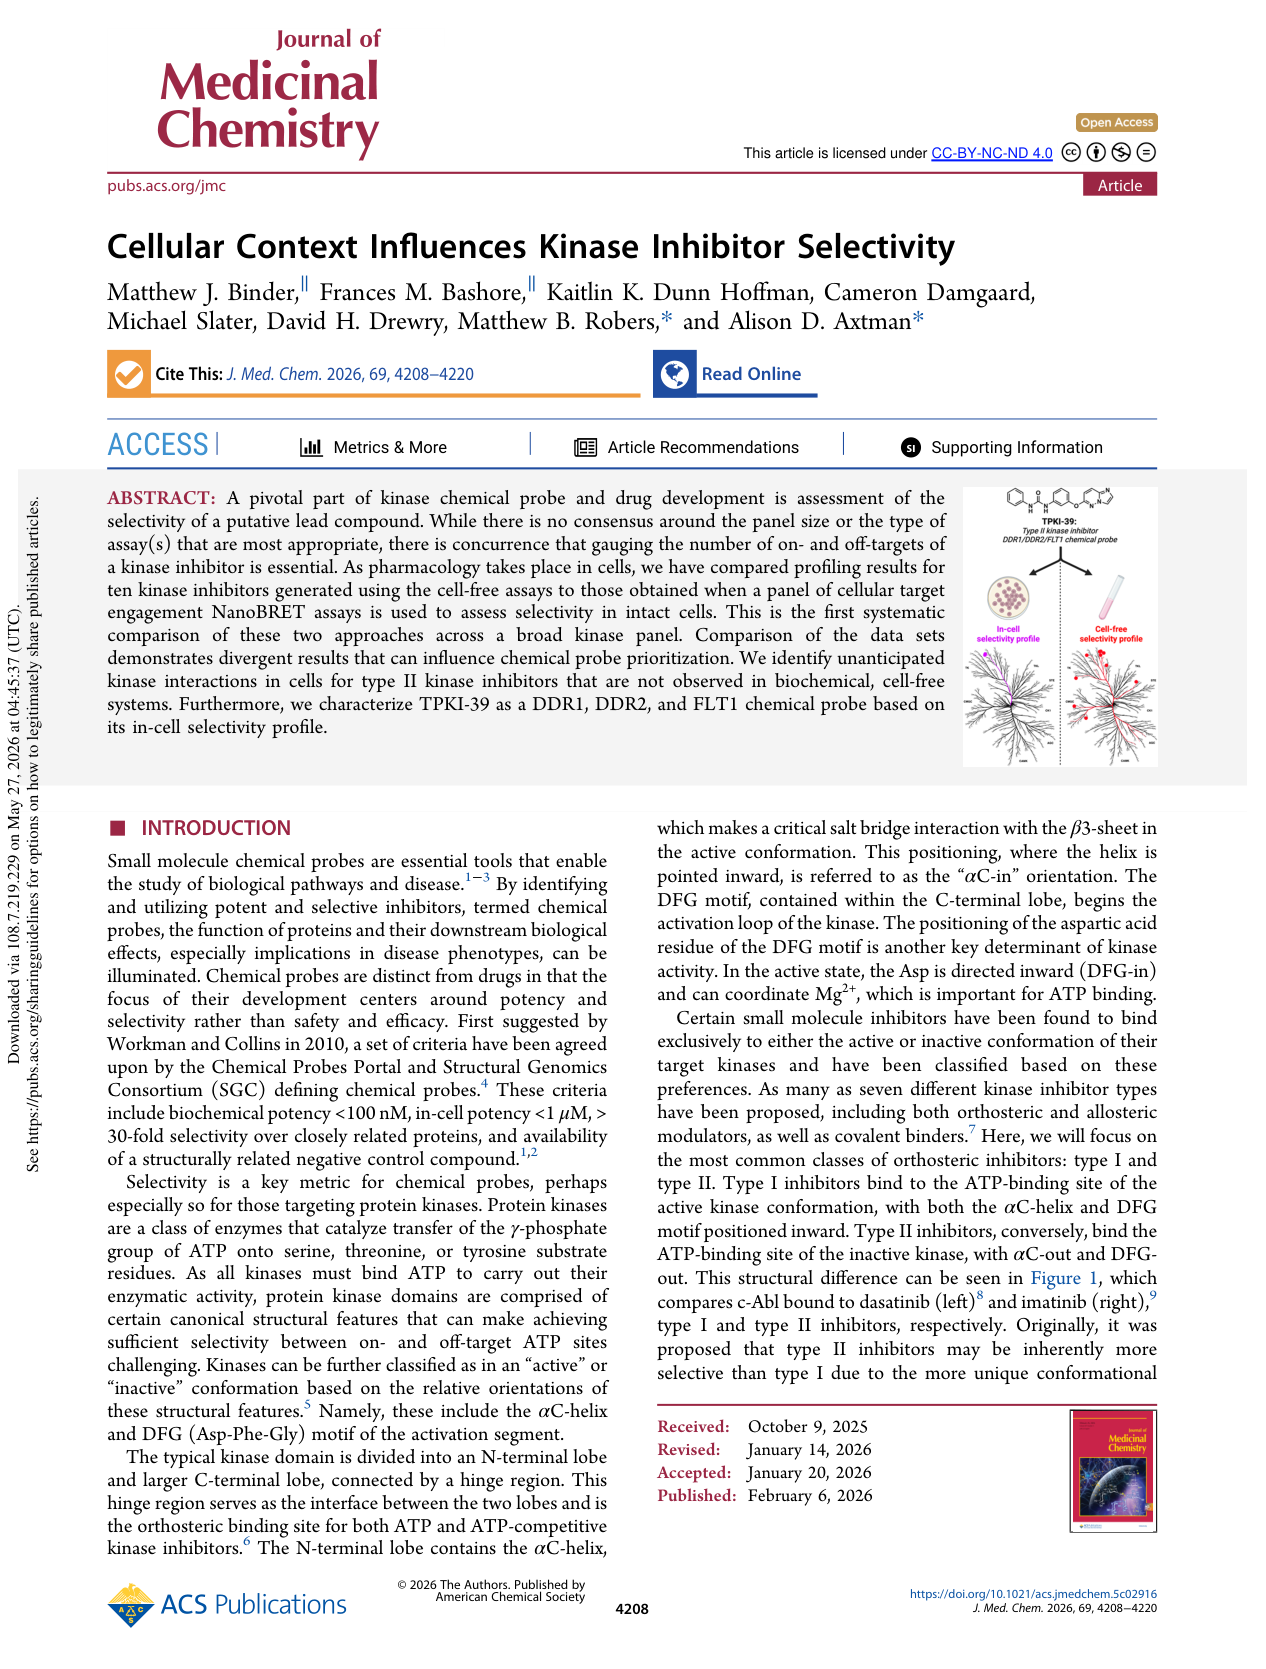

In [40]:
# Render one PDF page as an image for inspection.
from IPython.display import display, Image

with pymupdf.open(course_dataset_dir / "1.pdf") as pdf:
    page = pdf[0]
    page_image = page.get_pixmap(dpi=150, alpha=False)

display(Image(data=page_image.tobytes("png")))

In [41]:
# Load MolDetv2 from the project folder.
from ultralytics import YOLO

detector_path = Path.cwd() / "moldet_v2_yolo11n_960_doc.pt"

print("Detector file found:", detector_path.is_file(), flush=True)

detector = YOLO(str(detector_path))

print("MolDetv2 loaded successfully!")

Detector file found: True
MolDetv2 loaded successfully!


Molecular drawings detected: 1


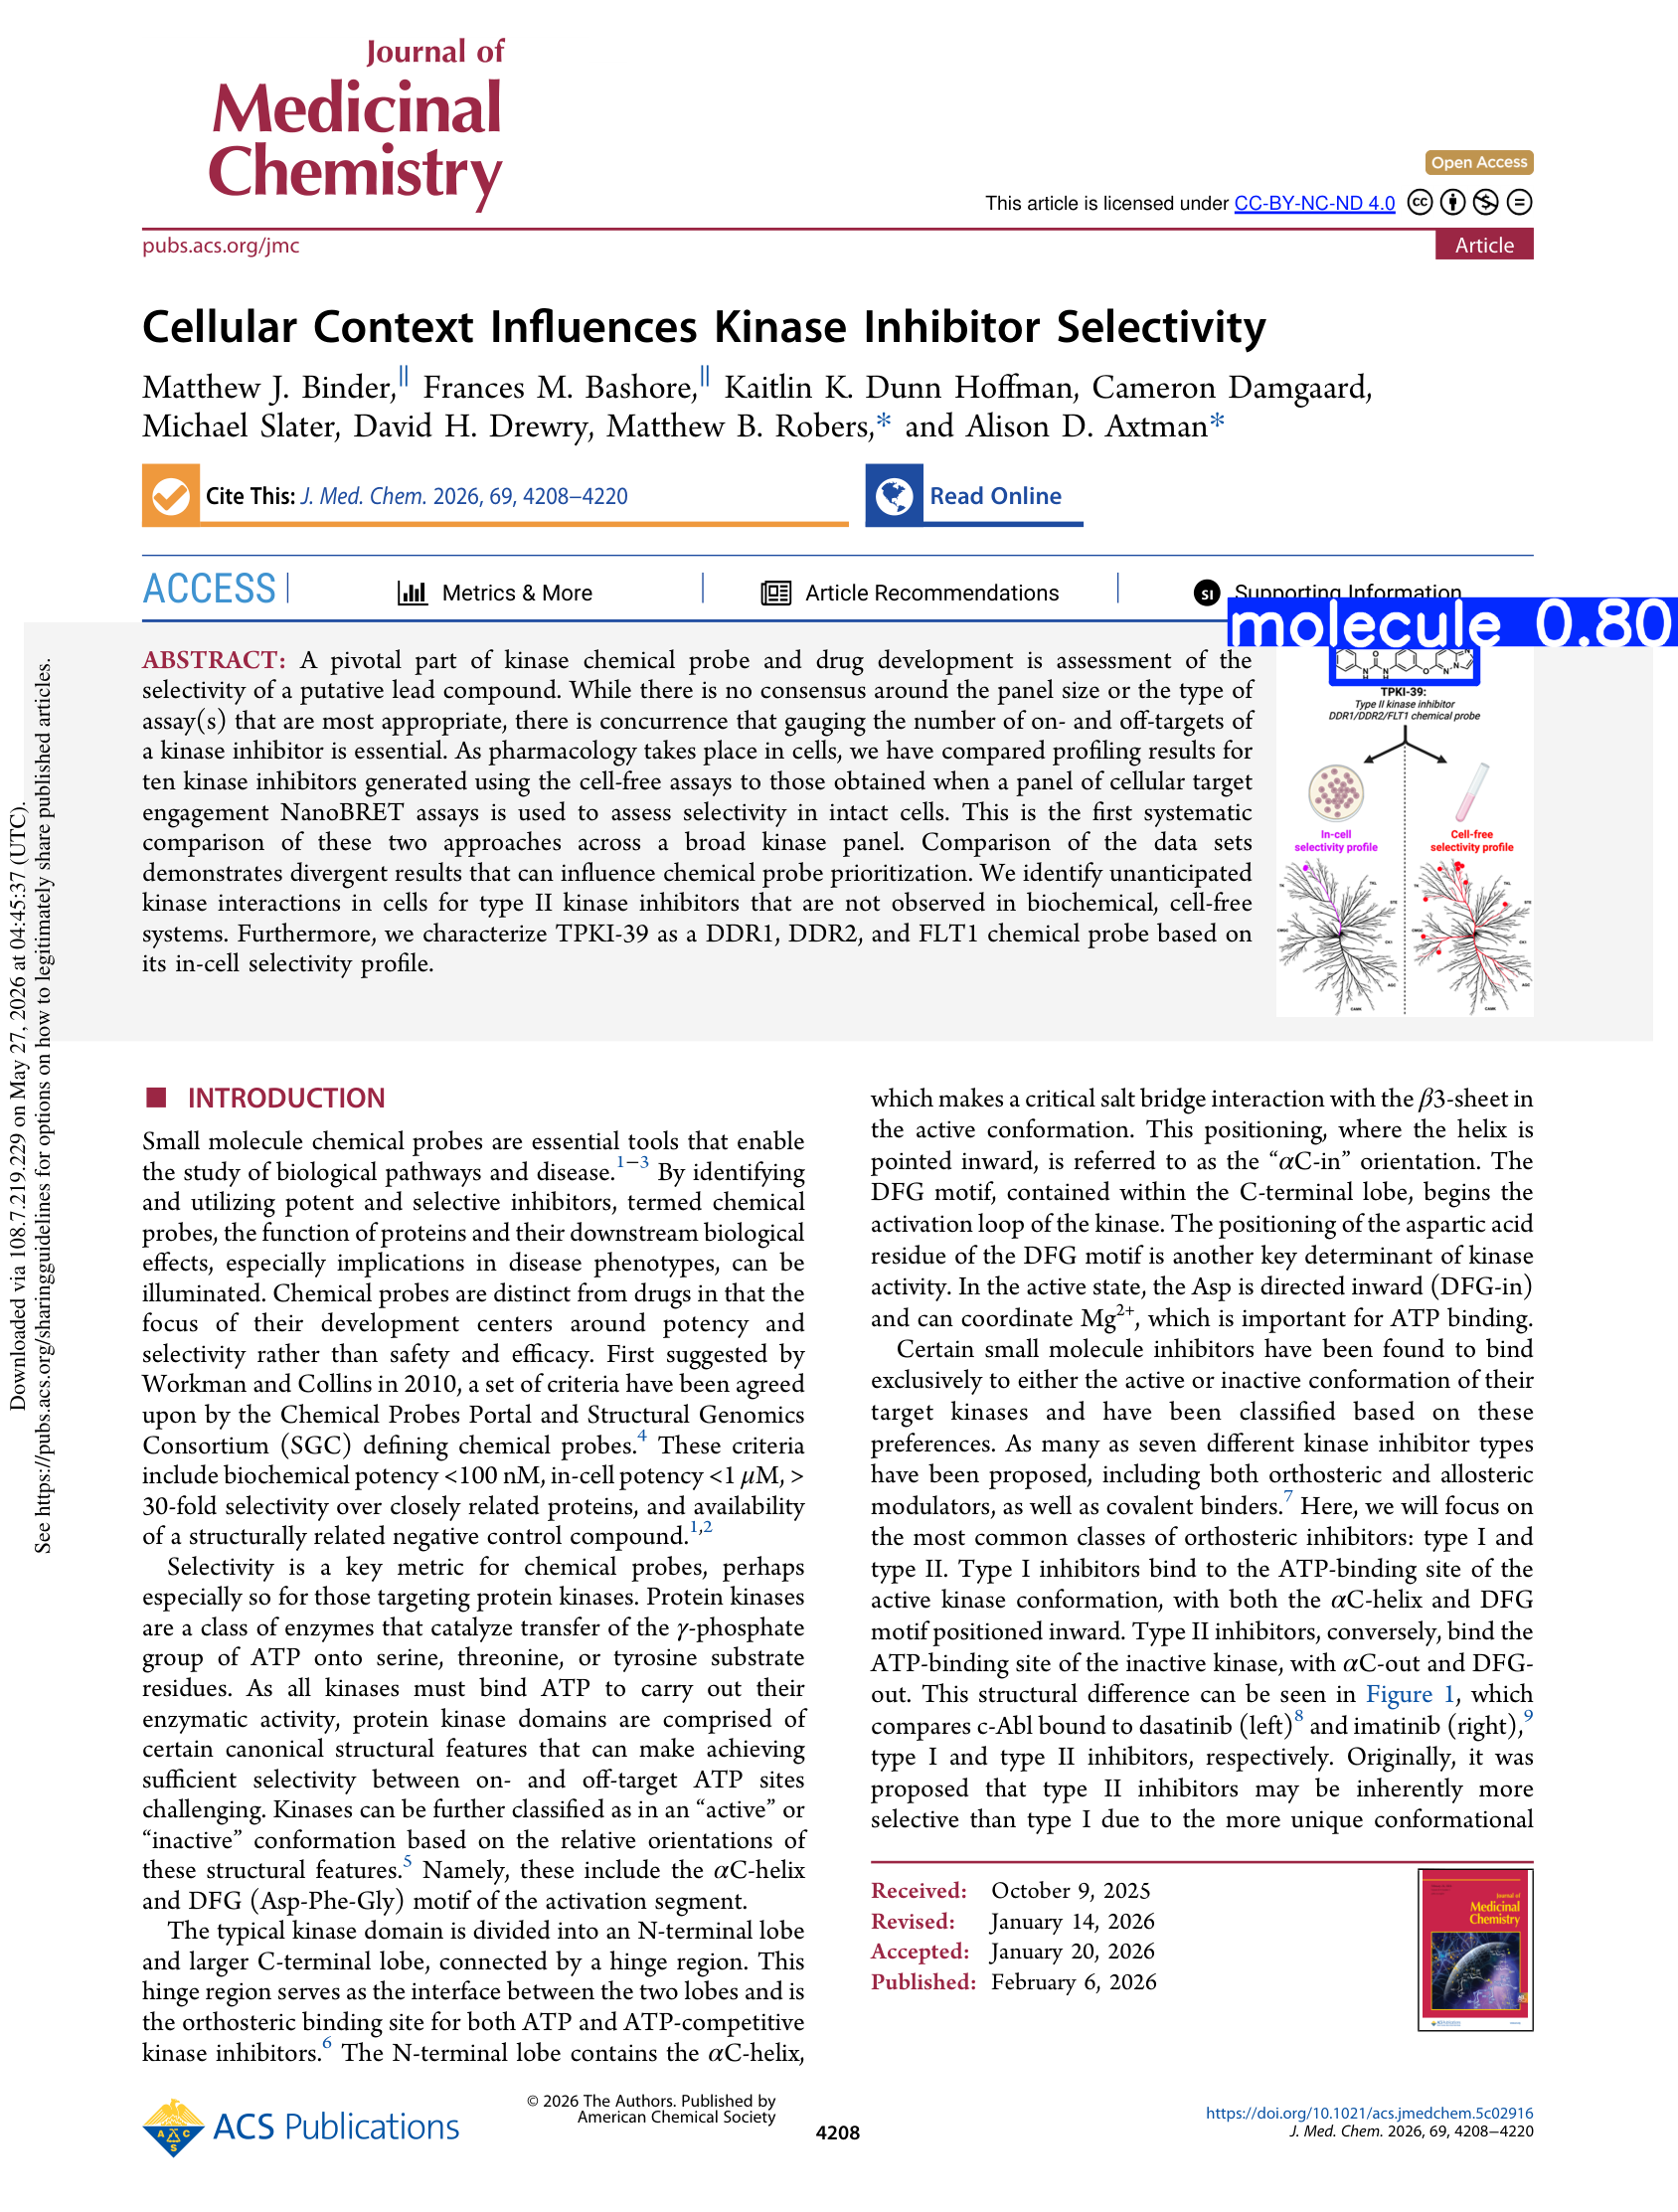

In [42]:
# Detect molecular drawings on one PDF page.
from PIL import Image as PILImage
from IPython.display import display

with pymupdf.open(course_dataset_dir / "1.pdf") as pdf:
    pix = pdf[0].get_pixmap(dpi=200, alpha=False)

page_image = PILImage.frombytes(
    "RGB", (pix.width, pix.height), pix.samples
)

detection = detector.predict(
    source=page_image,
    imgsz=960,
    conf=0.5,
    device="cpu",
    verbose=False
)[0]

print("Molecular drawings detected:", len(detection.boxes))

# Show the page with detection boxes.
display(PILImage.fromarray(detection.plot()[:, :, ::-1]))

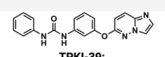

In [43]:
# Display the first detected molecular drawing.
if len(detection.boxes) > 0:
    box = detection.boxes.xyxy[0].cpu().tolist()
    x1, y1, x2, y2 = box

    # Add a small margin around the detected structure.
    margin = 10
    crop_box = (
        max(0, int(x1) - margin),
        max(0, int(y1) - margin),
        min(page_image.width, int(x2) + margin),
        min(page_image.height, int(y2) + margin)
    )

    test_crop = page_image.crop(crop_box)
    display(test_crop)
else:
    print("No molecular drawings detected on this page.")

In [44]:
# Load the chemical structure recognizer.
import sys
import torch

biominer_dir = Path.cwd() / "BioMiner-main"
molscribe_dir = biominer_dir / "BioMiner" / "MolScribe"

if str(molscribe_dir) not in sys.path:
    sys.path.insert(0, str(molscribe_dir))

from molscribe import MolGlyph

model_path = biominer_dir / "molglyph_large.pt"
print("MolGlyph file found:", model_path.is_file(), flush=True)

print("Loading MolGlyph—please wait...", flush=True)
model = MolGlyph(str(model_path), torch.device("cpu"))

print("MolGlyph loaded successfully!")

MolGlyph file found: True
Loading MolGlyph—please wait...
MolGlyph loaded successfully!


In [45]:
# Save the test crop and generate its raw prediction.
course_results_dir = Path.cwd() / "course_results"
course_results_dir.mkdir(exist_ok=True)

test_crop_path = course_results_dir / "paper_1_page_1_test_crop.png"
test_crop.save(test_crop_path)

raw_prediction = model.predict_image_file(
    str(test_crop_path),
    return_confidence=False
)

print("Raw prediction:", raw_prediction)

Raw prediction: O=C(Nc1ccccc1)Nc1cccc(Oc2ccc3nccn3n2)c1<sep>


In [46]:
# Load BioMiner's SMILES conversion utilities.
import importlib.util

utils_path = biominer_dir / "BioMiner" / "commons" / "molglyph_utils.py"

spec = importlib.util.spec_from_file_location(
    "molglyph_conversion", utils_path
)
molglyph_conversion = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = molglyph_conversion
spec.loader.exec_module(molglyph_conversion)


def convert_prediction(raw_output):
    if not isinstance(raw_output, str) or "<sep>" not in raw_output:
        raise ValueError("Prediction is missing the <sep> separator.")

    base_smiles, extension = raw_output.split("<sep>", 1)

    if "<r>" in extension or "<c>" in extension:
        return None

    refactored = molglyph_conversion.get_refactor(
        molglyph_conversion.Translator.refactor(raw_output)
    )

    return molglyph_conversion.get_new_smiles(
        refactored, base_smiles, extension
    )


test_smiles = convert_prediction(raw_prediction)
print("Converted SMILES:", test_smiles)

Converted SMILES: O=C(Nc1ccccc1)Nc1cccc(Oc2ccc3nccn3n2)c1


Prediction is valid: True
Canonical SMILES: O=C(Nc1ccccc1)Nc1cccc(Oc2ccc3nccn3n2)c1


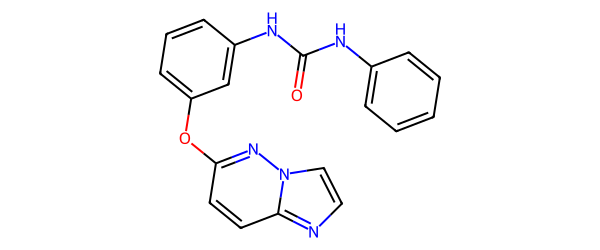

In [47]:
# Validate and display the predicted molecular structure.
from rdkit import Chem
from rdkit.Chem import Draw

test_molecule = Chem.MolFromSmiles(test_smiles)

print("Prediction is valid:", test_molecule is not None)

if test_molecule is not None:
    print(
        "Canonical SMILES:",
        Chem.MolToSmiles(test_molecule, isomericSmiles=True)
    )
    display(Draw.MolToImage(test_molecule, size=(600, 250)))

In [48]:
# Find the reference using the molecule's printed label.
paper_1_references = course_references[
    course_references["paperID"] == 1
].copy()

normalized_names = (
    paper_1_references["name of molecule"]
    .astype(str)
    .str.replace(r"[^A-Za-z0-9]", "", regex=True)
    .str.upper()
)

test_reference = paper_1_references[
    normalized_names == "TPKI39"
]

print("Matching reference rows:", len(test_reference))
display(test_reference)

Matching reference rows: 1


,paperID,name of molecule,canonical_SMILES
16,1,TPKI-39,O=C(Nc1ccccc1)Nc1cccc(Oc2ccc3nccn3n2)c1


In [49]:
# Compare the prediction with the label-matched reference.
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator

reference_smiles = test_reference.iloc[0]["canonical_SMILES"]
reference_molecule = Chem.MolFromSmiles(reference_smiles)

if reference_molecule is None or test_molecule is None:
    print("Cannot compare: reference or prediction is invalid.")
else:
    reference_canonical = Chem.MolToSmiles(
        reference_molecule, isomericSmiles=True
    )
    prediction_canonical = Chem.MolToSmiles(
        test_molecule, isomericSmiles=True
    )

    fingerprint_generator = rdFingerprintGenerator.GetMorganGenerator(
        radius=2,
        fpSize=2048,
        includeChirality=True
    )

    similarity = DataStructs.TanimotoSimilarity(
        fingerprint_generator.GetFingerprint(reference_molecule),
        fingerprint_generator.GetFingerprint(test_molecule)
    )

    print("Exact match:", reference_canonical == prediction_canonical)
    print("Tanimoto similarity:", round(similarity, 4))

Exact match: True
Tanimoto similarity: 1.0


## Initial pipeline check

MolDetv2 detected a molecular drawing on page 1 of Paper 1.
MolGlyph recognized the cropped drawing and BioMiner utilities converted
the output into SMILES.

The drawing was manually identified by its printed label, TPKI-39,
and compared with the corresponding reference:
- Exact match: True
- Tanimoto similarity: 1.0

This is a single-example check, not the overall benchmark result.

In [50]:
# Detect molecular drawings and save crops with their page locations.
import time

crops_dir = course_results_dir / "crops"
crops_dir.mkdir(exist_ok=True)

crop_records = []
page_records = []

for paper_id in [1, 2, 4, 6, 16, 19]:
    with pymupdf.open(course_dataset_dir / f"{paper_id}.pdf") as pdf:
        for page_number, page in enumerate(pdf, start=1):
            started = time.perf_counter()
            pix = page.get_pixmap(dpi=200, alpha=False)
            image = PILImage.frombytes(
                "RGB", (pix.width, pix.height), pix.samples
            )

            result = detector.predict(
                source=image,
                imgsz=960,
                conf=0.5,
                device="cpu",
                verbose=False
            )[0]

            for crop_number, box in enumerate(result.boxes, start=1):
                x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()

                crop_box = (
                    max(0, int(x1) - 10),
                    max(0, int(y1) - 10),
                    min(image.width, int(x2) + 10),
                    min(image.height, int(y2) + 10)
                )

                crop_path = crops_dir / (
                    f"paper_{paper_id}_page_{page_number}"
                    f"_crop_{crop_number}.png"
                )
                image.crop(crop_box).save(crop_path)

                crop_records.append({
                    "paperID": paper_id,
                    "page": page_number,
                    "crop_number": crop_number,
                    "image_path": crop_path.relative_to(
                        Path.cwd()
                    ).as_posix(),
                    "detector_confidence": float(box.conf.item()),
                    "x1": x1,
                    "y1": y1,
                    "x2": x2,
                    "y2": y2,
                    "render_dpi": 200
                })

            page_records.append({
                "paperID": paper_id,
                "page": page_number,
                "detections": len(result.boxes),
                "processing_seconds": time.perf_counter() - started
            })

            # Save progress after every page.
            pd.DataFrame(crop_records).to_csv(
                course_results_dir / "detected_crops.csv", index=False
            )
            pd.DataFrame(page_records).to_csv(
                course_results_dir / "page_detection_summary.csv",
                index=False
            )

            print(
                f"Paper {paper_id}, page {page_number}/{len(pdf)}: "
                f"{len(result.boxes)} drawings",
                flush=True
            )

print(f"\nFinished. Total crops saved: {len(crop_records)}")

Paper 1, page 1/13: 1 drawings
Paper 1, page 2/13: 0 drawings
Paper 1, page 3/13: 4 drawings
Paper 1, page 4/13: 3 drawings
Paper 1, page 5/13: 0 drawings
Paper 1, page 6/13: 3 drawings
Paper 1, page 7/13: 0 drawings
Paper 1, page 8/13: 7 drawings
Paper 1, page 9/13: 0 drawings
Paper 1, page 10/13: 0 drawings
Paper 1, page 11/13: 0 drawings
Paper 1, page 12/13: 0 drawings
Paper 1, page 13/13: 0 drawings
Paper 2, page 1/19: 0 drawings
Paper 2, page 2/19: 4 drawings
Paper 2, page 3/19: 5 drawings
Paper 2, page 4/19: 7 drawings
Paper 2, page 5/19: 64 drawings
Paper 2, page 6/19: 0 drawings
Paper 2, page 7/19: 1 drawings
Paper 2, page 8/19: 0 drawings
Paper 2, page 9/19: 0 drawings
Paper 2, page 10/19: 0 drawings
Paper 2, page 11/19: 0 drawings
Paper 2, page 12/19: 0 drawings
Paper 2, page 13/19: 0 drawings
Paper 2, page 14/19: 0 drawings
Paper 2, page 15/19: 0 drawings
Paper 2, page 16/19: 0 drawings
Paper 2, page 17/19: 0 drawings
Paper 2, page 18/19: 0 drawings
Paper 2, page 19/19: 0 dr

In [51]:
# Compare detection counts with reference counts.
detected_crops = pd.read_csv(
    course_results_dir / "detected_crops.csv"
)

detection_counts = detected_crops.groupby("paperID").size()
reference_counts = course_references.groupby("paperID").size()

paper_summary = pd.DataFrame({
    "reference_entries": reference_counts,
    "detected_crops": detection_counts
}).fillna(0).astype(int)

display(paper_summary)

,reference_entries,detected_crops
paperID,,
1,17,18
2,34,81
4,61,75
6,1,1
16,4,8
19,105,52


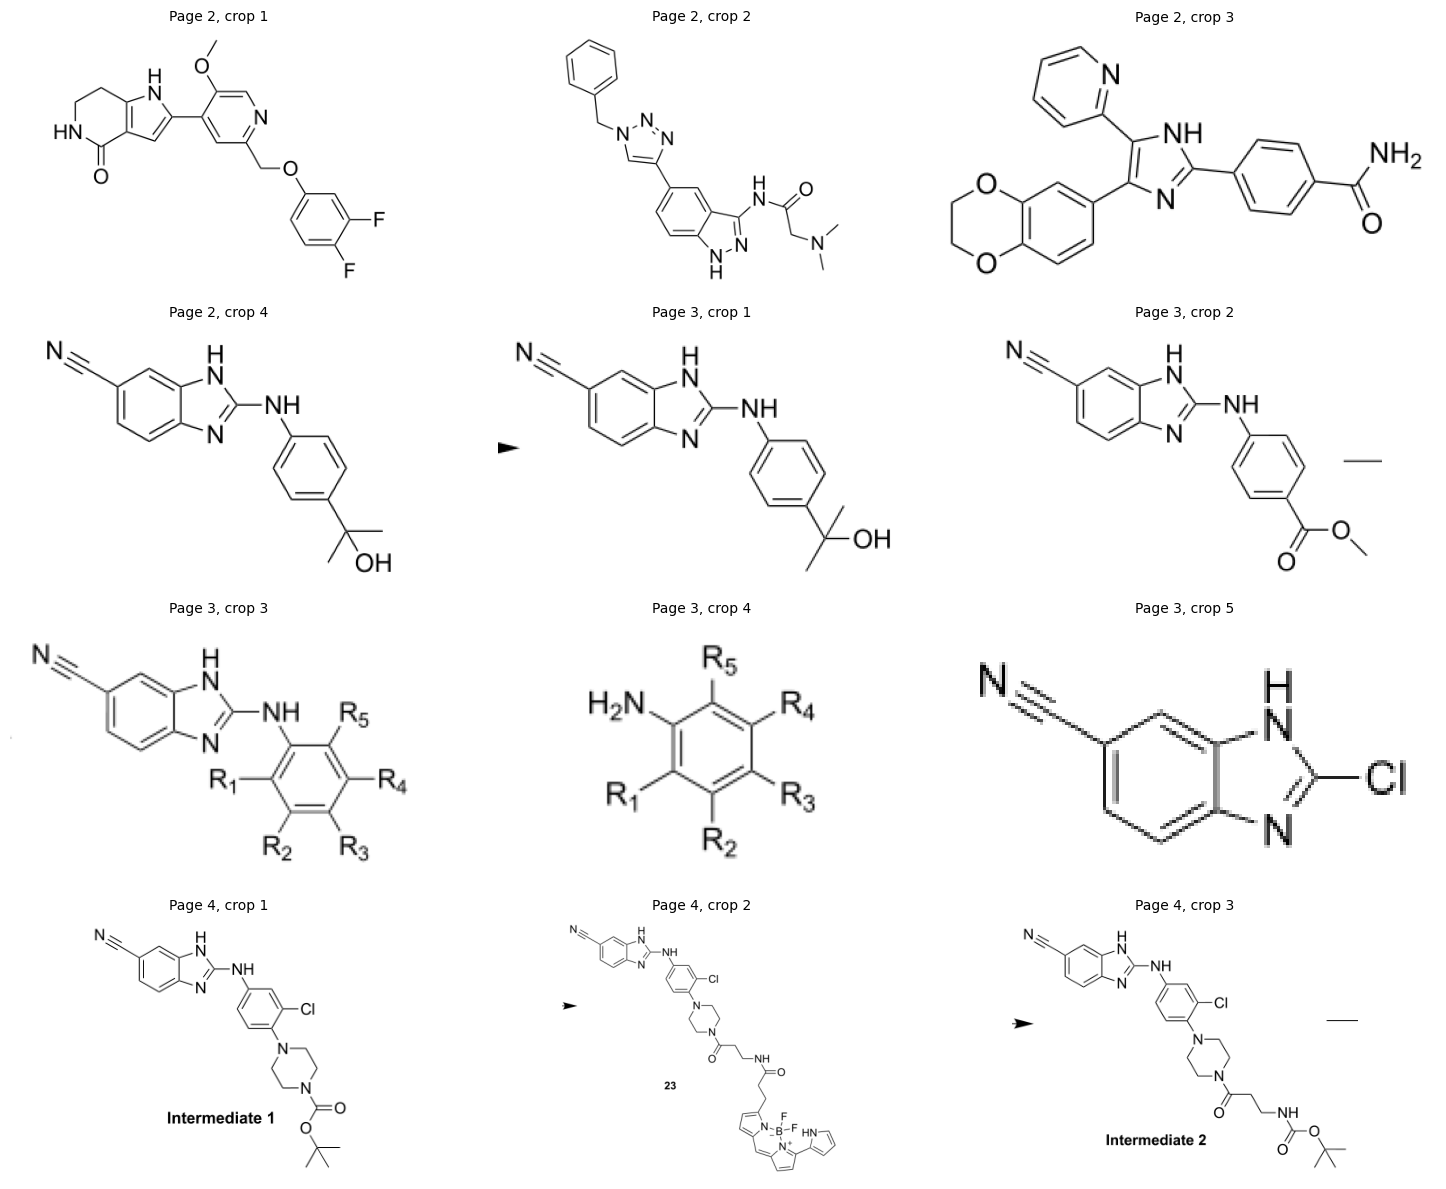

In [52]:
# Inspect detected crops before running recognition on all of them.
import matplotlib.pyplot as plt

preview_rows = detected_crops[
    detected_crops["paperID"] == 2
].head(12)

fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, (_, row) in zip(axes.flat, preview_rows.iterrows()):
    with PILImage.open(Path(row["image_path"])) as image:
        ax.imshow(image)

    ax.set_title(
        f"Page {int(row['page'])}, crop {int(row['crop_number'])}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [53]:
# Recognize every detected crop and save progress after each prediction.
import time

prediction_records = []

for number, (_, row) in enumerate(
    detected_crops.iterrows(), start=1
):
    record = row.to_dict()
    record.update({
        "raw_prediction": None,
        "predicted_smiles": None,
        "canonical_prediction": None,
        "prediction_valid": False,
        "status": "error",
        "error_message": None
    })

    started = time.perf_counter()

    try:
        raw = model.predict_image_file(
            str(Path(row["image_path"])),
            return_confidence=False
        )
        record["raw_prediction"] = raw

        smiles = convert_prediction(raw)
        record["predicted_smiles"] = smiles

        if not smiles:
            record["status"] = "unresolved"
        else:
            molecule = Chem.MolFromSmiles(smiles)

            if molecule is None:
                record["status"] = "invalid_prediction"
            else:
                record["prediction_valid"] = True
                record["canonical_prediction"] = Chem.MolToSmiles(
                    molecule, isomericSmiles=True
                )
                record["status"] = "valid"

    except Exception as error:
        record["error_message"] = (
            f"{type(error).__name__}: {error}"
        )

    record["recognition_seconds"] = time.perf_counter() - started
    prediction_records.append(record)

    pd.DataFrame(prediction_records).to_csv(
        course_results_dir / "course_predictions.csv",
        index=False
    )

    print(
        f"{number}/{len(detected_crops)} | "
        f"Paper {int(row['paperID'])}, "
        f"page {int(row['page'])} | {record['status']}",
        flush=True
    )

course_predictions = pd.DataFrame(prediction_records)

print("\nFinished:")
print(course_predictions["status"].value_counts())

1/235 | Paper 1, page 1 | valid
2/235 | Paper 1, page 3 | valid
3/235 | Paper 1, page 3 | valid
4/235 | Paper 1, page 3 | valid
5/235 | Paper 1, page 3 | valid
6/235 | Paper 1, page 4 | valid
7/235 | Paper 1, page 4 | valid
8/235 | Paper 1, page 4 | valid
9/235 | Paper 1, page 6 | valid
10/235 | Paper 1, page 6 | valid
11/235 | Paper 1, page 6 | valid
12/235 | Paper 1, page 8 | valid
13/235 | Paper 1, page 8 | valid
14/235 | Paper 1, page 8 | valid
15/235 | Paper 1, page 8 | valid
16/235 | Paper 1, page 8 | valid
17/235 | Paper 1, page 8 | valid
18/235 | Paper 1, page 8 | valid
19/235 | Paper 2, page 2 | valid
20/235 | Paper 2, page 2 | valid
21/235 | Paper 2, page 2 | valid
22/235 | Paper 2, page 2 | valid
23/235 | Paper 2, page 3 | valid
24/235 | Paper 2, page 3 | valid
25/235 | Paper 2, page 3 | valid
26/235 | Paper 2, page 3 | valid
27/235 | Paper 2, page 3 | valid
28/235 | Paper 2, page 4 | valid
29/235 | Paper 2, page 4 | valid
30/235 | Paper 2, page 4 | valid
31/235 | Paper 2, p

In [54]:
# Validate and canonicalize the supplied reference SMILES.
def canonicalize_smiles(smiles):
    if not isinstance(smiles, str):
        return None

    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        return None

    return Chem.MolToSmiles(molecule, isomericSmiles=True)


course_references["canonical_reference"] = (
    course_references["canonical_SMILES"].apply(canonicalize_smiles)
)

print("Reference entries:", len(course_references))
print(
    "Readable references:",
    course_references["canonical_reference"].notna().sum()
)

# Check whether multiple reference entries describe the same molecule.
readable_references = course_references.dropna(
    subset=["canonical_reference"]
)

print(
    "Unique structures within papers:",
    len(readable_references.drop_duplicates(
        subset=["paperID", "canonical_reference"]
    ))
)

Reference entries: 222
Readable references: 222
Unique structures within papers: 220


In [55]:
# Measure exact recovery of unique reference structures within each paper.
recovery_records = []

for paper_id in [1, 2, 4, 6, 16, 19]:
    references = set(
        course_references.loc[
            course_references["paperID"] == paper_id,
            "canonical_reference"
        ].dropna()
    )

    predictions = set(
        course_predictions.loc[
            (course_predictions["paperID"] == paper_id)
            & (course_predictions["status"] == "valid"),
            "canonical_prediction"
        ].dropna()
    )

    recovered = references & predictions

    recovery_records.append({
        "paperID": paper_id,
        "unique_reference_structures": len(references),
        "unique_valid_predictions": len(predictions),
        "exactly_recovered_structures": len(recovered),
        "exact_recovery_rate": len(recovered) / len(references)
    })

exact_recovery = pd.DataFrame(recovery_records)

exact_recovery.to_csv(
    course_results_dir / "exact_structure_recovery.csv",
    index=False
)

display(exact_recovery)

total_references = exact_recovery["unique_reference_structures"].sum()
total_recovered = exact_recovery["exactly_recovered_structures"].sum()

print(
    f"Overall exact recovery: {total_recovered}/{total_references}"
    f" ({total_recovered / total_references:.1%})"
)

,paperID,unique_reference_structures,unique_valid_predictions,exactly_recovered_structures,exact_recovery_rate
0,1,17,17,17,1.000000
1,2,34,30,9,0.264706
2,4,60,57,14,0.233333
3,6,1,1,0,0.000000
4,16,4,7,1,0.250000
5,19,104,47,19,0.182692


Overall exact recovery: 60/220 (27.3%)


In [56]:
# Calculate best available similarity for each unique reference.
similarity_records = []

unique_references = course_references.drop_duplicates(
    subset=["paperID", "canonical_reference"]
)

for paper_id in [1, 2, 4, 6, 16, 19]:
    paper_predictions = course_predictions.loc[
        (course_predictions["paperID"] == paper_id)
        & (course_predictions["status"] == "valid")
    ].drop_duplicates(subset=["canonical_prediction"])

    prediction_smiles = paper_predictions[
        "canonical_prediction"
    ].tolist()

    prediction_fingerprints = [
        fingerprint_generator.GetFingerprint(Chem.MolFromSmiles(s))
        for s in prediction_smiles
    ]

    for _, reference in unique_references[
        unique_references["paperID"] == paper_id
    ].iterrows():
        reference_fp = fingerprint_generator.GetFingerprint(
            Chem.MolFromSmiles(reference["canonical_reference"])
        )

        scores = [
            DataStructs.TanimotoSimilarity(reference_fp, fp)
            for fp in prediction_fingerprints
        ]

        best_index = max(range(len(scores)), key=scores.__getitem__) \
            if scores else None

        similarity_records.append({
            "paperID": paper_id,
            "reference_name": reference["name of molecule"],
            "canonical_reference": reference["canonical_reference"],
            "exactly_recovered": (
                reference["canonical_reference"] in prediction_smiles
            ),
            "best_available_tanimoto": (
                scores[best_index] if best_index is not None else 0.0
            ),
            "closest_prediction": (
                prediction_smiles[best_index]
                if best_index is not None else None
            )
        })

reference_recovery = pd.DataFrame(similarity_records)
reference_recovery.to_csv(
    course_results_dir / "reference_recovery_details.csv",
    index=False
)

display(
    reference_recovery.groupby("paperID")[
        "best_available_tanimoto"
    ].mean().to_frame()
)

print(
    "Overall mean best available similarity:",
    round(reference_recovery["best_available_tanimoto"].mean(), 4)
)

,best_available_tanimoto
paperID,
1,1.000000
2,0.695489
4,0.739938
6,0.932203
16,0.741923
19,0.748791


Overall mean best available similarity: 0.7583


Reference name: NR-7h
Reference: Cc1cc(C(=O)NCCCCc2cn(CCCC(=O)NCCCCNc3cccc4c3C(=O)N(C3CCC(=O)NC3=O)C4=O)nn2)ccc1-n1c(C)cc(OCc2ccc(F)cc2F)c(Br)c1=O
Prediction: Cc1ccc(C(=O)NCCCCc2cn(CCCC(=O)NCCCCNc3cccc4c3C(=O)N(C3CCC(=O)NC3=O)C4=O)nn2)cc1-n1c(C)cc(OCc2ccc(F)cc2F)c(Br)c1=O


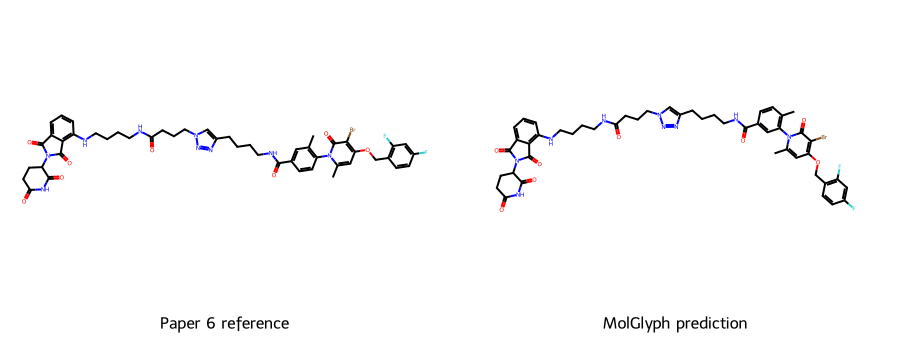

In [57]:
# Inspect Paper 6's reference and prediction side by side.
paper6_reference = course_references.loc[
    course_references["paperID"] == 6
].iloc[0]

paper6_prediction = course_predictions.loc[
    (course_predictions["paperID"] == 6)
    & (course_predictions["status"] == "valid")
].iloc[0]

print("Reference name:", paper6_reference["name of molecule"])
print("Reference:", paper6_reference["canonical_reference"])
print("Prediction:", paper6_prediction["canonical_prediction"])

molecules = [
    Chem.MolFromSmiles(paper6_reference["canonical_reference"]),
    Chem.MolFromSmiles(paper6_prediction["canonical_prediction"])
]

display(Draw.MolsToGridImage(
    molecules,
    molsPerRow=2,
    subImgSize=(450, 350),
    legends=["Paper 6 reference", "MolGlyph prediction"]
))

In [58]:
# Compare molecular formulas and atom counts for Paper 6.
from rdkit.Chem import rdMolDescriptors
from collections import Counter

for label, molecule in zip(
    ["Reference", "Prediction"], molecules
):
    print(label)
    print("Formula:", rdMolDescriptors.CalcMolFormula(molecule))
    print("Atom counts:", dict(Counter(
        atom.GetSymbol() for atom in molecule.GetAtoms()
    )))
    print()

Reference
Formula: C48H50BrF2N9O8
Atom counts: {'C': 48, 'O': 8, 'N': 9, 'F': 2, 'Br': 1}

Prediction
Formula: C48H50BrF2N9O8
Atom counts: {'C': 48, 'O': 8, 'N': 9, 'F': 2, 'Br': 1}



In [59]:
# Print the Paper 6 SMILES clearly for comparison.
print("REFERENCE:")
print(paper6_reference["canonical_reference"])

print("\nPREDICTION:")
print(paper6_prediction["canonical_prediction"])

# Check connectivity without stereochemistry.
print(
    "\nSame structure when stereochemistry is ignored:",
    Chem.MolToSmiles(molecules[0], isomericSmiles=False)
    == Chem.MolToSmiles(molecules[1], isomericSmiles=False)
)

REFERENCE:
Cc1cc(C(=O)NCCCCc2cn(CCCC(=O)NCCCCNc3cccc4c3C(=O)N(C3CCC(=O)NC3=O)C4=O)nn2)ccc1-n1c(C)cc(OCc2ccc(F)cc2F)c(Br)c1=O

PREDICTION:
Cc1ccc(C(=O)NCCCCc2cn(CCCC(=O)NCCCCNc3cccc4c3C(=O)N(C3CCC(=O)NC3=O)C4=O)nn2)cc1-n1c(C)cc(OCc2ccc(F)cc2F)c(Br)c1=O

Same structure when stereochemistry is ignored: False


## Failure case in Paper 6

The NR-7h prediction had a Tanimoto similarity of 0.9322 but did
not exactly match the reference.

Both structures had the same molecular formula, C48H50BrF2N9O8.
Comparing their SMILES showed that the amide-containing linker
was attached at a different position on the substituted benzene ring.
The mismatch remained when stereochemistry was ignored.

This example shows that valid SMILES, matching molecular formulas,
and high fingerprint similarity do not guarantee the correct structure.
The original PDF drawing must be checked to determine whether the
disagreement comes from recognition or the supplied reference.

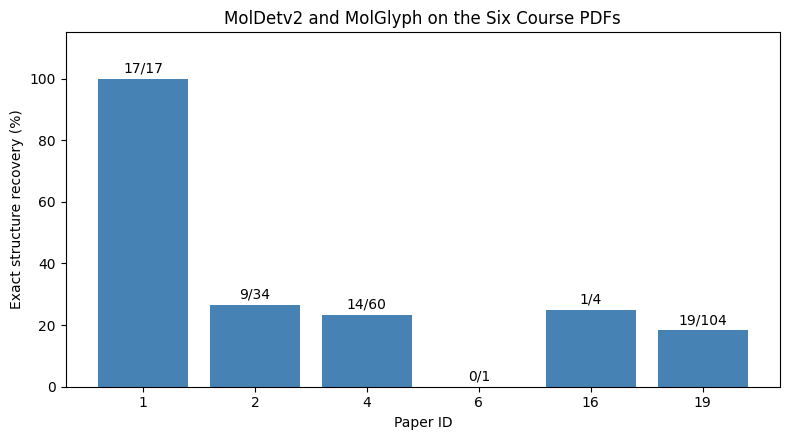

In [60]:
# Plot exact structure recovery for each course paper.
fig, ax = plt.subplots(figsize=(8, 4.5))

percentages = exact_recovery["exact_recovery_rate"] * 100

bars = ax.bar(
    exact_recovery["paperID"].astype(str),
    percentages,
    color="steelblue"
)

for bar, (_, row) in zip(bars, exact_recovery.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{int(row['exactly_recovered_structures'])}/"
        f"{int(row['unique_reference_structures'])}",
        ha="center"
    )

ax.set_xlabel("Paper ID")
ax.set_ylabel("Exact structure recovery (%)")
ax.set_title("MolDetv2 and MolGlyph on the Six Course PDFs")
ax.set_ylim(0, 115)

fig.tight_layout()
fig.savefig(
    course_results_dir / "exact_recovery_by_paper.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [61]:
# Save the main benchmark results in one summary file.
page_summary = pd.read_csv(
    course_results_dir / "page_detection_summary.csv"
)

benchmark_summary = pd.DataFrame([{
    "pipeline": "MolDetv2 + MolGlyph",
    "papers": 6,
    "pages_processed": len(page_summary),
    "reference_entries": len(course_references),
    "unique_references_within_papers": len(reference_recovery),
    "detected_crops": len(course_predictions),
    "valid_predictions": int(
        (course_predictions["status"] == "valid").sum()
    ),
    "unresolved_predictions": int(
        (course_predictions["status"] == "unresolved").sum()
    ),
    "invalid_predictions": int(
        (course_predictions["status"] == "invalid_prediction").sum()
    ),
    "recognition_errors": int(
        (course_predictions["status"] == "error").sum()
    ),
    "exactly_recovered_structures": int(
        reference_recovery["exactly_recovered"].sum()
    ),
    "exact_structure_recovery_rate": (
        reference_recovery["exactly_recovered"].mean()
    ),
    "mean_best_available_tanimoto": (
        reference_recovery["best_available_tanimoto"].mean()
    ),
    "detection_stage_seconds": (
        page_summary["processing_seconds"].sum()
    ),
    "recognition_stage_seconds": (
        course_predictions["recognition_seconds"].sum()
    )
}])

benchmark_summary.to_csv(
    course_results_dir / "course_benchmark_summary.csv",
    index=False
)

display(benchmark_summary.T)

,0
pipeline,MolDetv2 + MolGlyph
papers,6
pages_processed,104
reference_entries,222
unique_references_within_papers,220
detected_crops,235
valid_predictions,229
unresolved_predictions,4
invalid_predictions,2
recognition_errors,0


## Benchmark summary and limitations

The MolDetv2 and MolGlyph pipeline processed all 104 pages across
the six course PDFs and produced 235 molecular crops.

Of these, 229 produced valid SMILES, four were unresolved, and two
were invalid. Validity means that RDKit could read a prediction;
it does not establish that the prediction is correct.

The pipeline exactly recovered 60 of 220 unique reference structures
within their respective papers, giving 27.3% exact structure recovery.
Repeated reference structures were counted once per paper.

The mean best available Tanimoto similarity was 0.7583. This compares
each reference with its closest prediction from the same paper.
Predictions can be reused in this comparison, so this diagnostic
score is not paired recognition accuracy or proof of correct labeling.

The benchmark evaluates detection followed by recognition. It does
not separately measure detection accuracy, automatically associate
structures with molecule names, or expand Markush structures.
Unrecovered references may reflect detection, recognition, conversion,
or representation differences and require further inspection.

Recorded processing took approximately 29 seconds for the detection
stage and 693 seconds for recognition, excluding model loading and
CSV checkpoint writes.

In [62]:
# Save dependency versions for the course PDF benchmark.
from importlib.metadata import version

packages = [
    "numpy", "pandas", "Pillow", "rdkit",
    "torch", "torchvision", "matplotlib",
    "opencv-python", "SmilesPE", "OpenNMT-py",
    "albumentations", "timm", "ipykernel",
    "PyMuPDF", "ultralytics"
]

requirements = [
    f"{package}=={version(package)}"
    for package in packages
]

requirements.append("./BioMiner-main/BioMiner/MolScribe")

Path("requirements_course.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print(Path("requirements_course.txt").read_text(encoding="utf-8"))

numpy==1.26.4
pandas==2.3.3
Pillow==12.3.0
rdkit==2026.9.1
torch==1.13.1
torchvision==0.14.1
matplotlib==3.10.9
opencv-python==4.11.0.86
SmilesPE==0.0.3
OpenNMT-py==2.2.0
albumentations==1.1.0
timm==0.4.12
ipykernel==7.3.0
PyMuPDF==1.28.2
ultralytics==8.4.178
./BioMiner-main/BioMiner/MolScribe



Recorded processing took approximately 30 seconds for the detection
stage and 716 seconds for recognition, excluding model loading and
CSV checkpoint writes.